# Feature importance — choosing and checking the features that matter

Two complementary studies:

- **Part A** works on the Drebin-drift table. It builds the binary feature matrix, ranks features two ways (a Random Forest, and the difference in class means), keeps the **top 1,000** as the *redefined* feature set, and sanity-checks the result — this redefined matrix is what the main detectors are trained on.
- **Part B** asks the trained model itself which features drive its decisions, using **Integrated Gradients** (Captum) on the earlier 6,693-feature DNN.

*Consolidated from `1_Feature_Importance.ipynb` (`mal_adv3`) and the first half of `Feature_importance_.ipynb` (`a_malware`). The second half of the latter — a PGD attack and adversarial training — belongs with the attacks and now lives in `03-attacks/`. Outputs cleared.*

## Part A — Ranking features on the Drebin-drift table

### Step 1 — Load the table and build the feature matrix

In [ ]:
# https://drive.google.com/file/d/1wU686D7BJyHbg3sa8y_08d0lEzA6qE8E/view?usp=sharing
import gdown
download_link = 'https://drive.google.com/uc?id=1wU686D7BJyHbg3sa8y_08d0lEzA6qE8E'
output_filepath = '/content/'
gdown.download(download_link, output_filepath)

In [ ]:
import pandas as pd
df = pd.read_parquet("/content/drebin_drift.parquet.zip")
df.head(3)

In [ ]:
df.rename(columns = {'feature':'Hardware Component', 'real_permission':'Used Permission', 'api_call':'Suspicious API Call', 'permission':'Requested Permission' }, inplace = True)

In [ ]:
df.head(3)

In [ ]:
df.columns

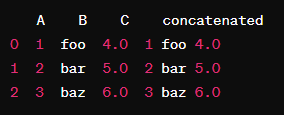

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Example documents
documents = [
    "This is the firstdocument.",
    "This document is the.econd_document.",
    "And this is the,thirdone.",
    "Is this the first document?",
]

# Create CountVectorizer object with modified token pattern
vectorizer = CountVectorizer(binary=True, token_pattern=r'\S+')

# Fit and transform the documents
X = vectorizer.fit_transform(documents)

# Convert sparse matrix to array for visualization
X_array = X.toarray()

# Print feature names (vocabulary)
print("Vocabulary:", vectorizer.get_feature_names_out())

# Print feature matrix
print("Feature Matrix:")
print(X_array)

In [ ]:
columns = ['Suspicious API Call','Requested Permission', 'url', 'provider', 'Hardware Component','intent', 'activity', 'call', 'service_receiver', 'Used Permission']
for column in columns:
  vectorizer = CountVectorizer(binary=True, token_pattern=r'\S+')
  X = vectorizer.fit_transform(df[str(column)])
  print(column , " : ",X.shape[1])

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

def preprocess_data(df):
    # Concatenate all columns into a single string
    df['concatenated'] = df.apply(lambda row: ' '.join(row.astype(str)), axis=1)
    return df['concatenated']

def extract_features(df):
    # Preprocess the data
    data = preprocess_data(df)

    # Use CountVectorizer to tokenize and one-hot encode the data
    vectorizer = CountVectorizer(binary=True, token_pattern=r'\S+')
    X = vectorizer.fit_transform(data)

    return X, vectorizer.vocabulary_

In [ ]:
# Assuming 'df' is your DataFrame
X, vocab = extract_features(df[['Suspicious API Call','Requested Permission', 'url', 'provider', 'Hardware Component','intent', 'activity', 'call', 'service_receiver', 'Used Permission']])

# X is now your feature matrix, and vocab contains the vocabulary
print(X.shape)  # Print shape of feature matrix

### Step 2 — Save the vocabulary

In [ ]:
import pickle

# Save the dictionary to a file
with open('vocab.pkl', 'wb') as f:
    pickle.dump(vocab, f)

In [ ]:
for i,j in enumerate(vocab.items()):
  print(j)
  if i>5:
    break

In [ ]:
def swap_keys_and_values(original_dict):
    new_dict = {value: key for key, value in original_dict.items()}
    return new_dict

# Create new dictionary with swapped keys and values
vocab_n = swap_keys_and_values(vocab)

In [ ]:
# Retrieve the first row of X
first_row = X[0]

# Get the indices where the values are non-zero (indicating the presence of a term)
nonzero_indices = first_row.nonzero()[1]

# Get the corresponding terms from the vocabulary
terms = [term for term, index in vocab.items() if index in nonzero_indices]

print("First row of X with corresponding vocabulary terms:")
for term in terms:
    print(term)

### Step 3 — Ranking 1: Random Forest importance

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

labels= list(df['label'])

# Step 1: Train a Random Forest Classifier
rf_classifier = RandomForestClassifier()
rf_classifier.fit(X, labels)

# Step 2: Access Feature Importances
feature_importances = rf_classifier.feature_importances_

# Step 3: Rank Features by Importance
# Get the indices that would sort the feature importances array in descending order
sorted_indices = np.argsort(feature_importances)[::-1]

# Print the top N features and their importance scores
N = 20  # Number of top features to display
print("Top", N, "features:")
print("{:<60} {:<20}".format("Feature", "Importance Score"))
print('----------------------------------------------------------------')
for i in range(N):
    feature_index = sorted_indices[i]
    importance_score = feature_importances[feature_index]
    print("{:<60} {:<20}".format(vocab_n[feature_index], importance_score))

In [ ]:
# Assuming 'sorted_indices' contains the indices of the top 1000 important features

# Select the indices of the top 1000 important features
top_indices = sorted_indices[:10000]

# Redefine X based on the top 1000 important features
X_redefined = X[:, top_indices]

# Now X_redefined contains only the top 1000 important features
X_redefined.shape

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

labels= list(df['label'])

# Split the data into training and testing sets (e.g., 80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_redefined, labels, test_size=0.2, random_state=42)

# Instantiate a Random Forest classifier
rf_classifier2 = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the classifier on the training data
rf_classifier2.fit(X_train, y_train)

# Predict the labels for the test set
y_pred = rf_classifier2.predict(X_test)

# Evaluate the classifier
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

In [ ]:
from sklearn.metrics import f1_score

# Calculate the F1 score
f1 = f1_score(y_test, y_pred)

print("F1 Score:", f1)

### Step 4 — Ranking 2: difference of class means

In [ ]:
from scipy import sparse
import torch

# Assuming your sparse matrix is named sparse_matrix
sparse.save_npz("sparse_matrix.npz", X_redefined)

# Convert labels to PyTorch tensor
labels_tensor = torch.tensor(labels, dtype=torch.float32).view(-1, 1)  # Reshape labels to match model output
torch.save(labels_tensor, 'labels.pt')

In [ ]:
# Convert a column to a NumPy array
labels = df['label'].values
labels.shape

In [ ]:
# Separate X based on labels
positive_indices = labels == 1
negative_indices = labels == 0

X_positive = X[positive_indices]
X_negative = X[negative_indices]

print("Positive samples shape:", X_positive.shape)
print("Negative samples shape:", X_negative.shape)

In [ ]:
# Sum each column of X_positive
positive_sums = X_positive.sum(axis=0)/X_positive.shape[0]
negative_sums = X_negative.sum(axis=0)/X_negative.shape[0]

In [ ]:
importance = abs(positive_sums - negative_sums)

# Find the indices of the top 1000 values
top_indices2 = np.argsort(importance)[0, -10000:]
top_indices2 = np.array(top_indices2)[0]

In [ ]:
len(set(top_indices2) - set(top_indices))

### Step 5 — The redefined matrix (top 1,000 features) and a first check

In [ ]:
# Redefine X based on the top 1000 important features
X_redefined2 = X[:, top_indices2]

# Now X_redefined contains only the top 1000 important features
X_redefined2.shape

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

labels= list(df['label'])

# Split the data into training and testing sets (e.g., 80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_redefined2, labels, test_size=0.2, random_state=42)

# Instantiate a Random Forest classifier
rf_classifier3 = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the classifier on the training data
rf_classifier3.fit(X_train, y_train)

# Predict the labels for the test set
y_pred = rf_classifier3.predict(X_test)

# Evaluate the classifier
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

### Step 6 — A quick DNN on the redefined features

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from scipy import sparse

In [ ]:
# Split data into train, validation, and test sets with stratified sampling
X_train_val, X_test, labels_train_val, labels_test = train_test_split(X_redefined2, labels_tensor, test_size=0.2, stratify=labels, random_state=42)
X_train, X_val, labels_train, labels_val = train_test_split(X_train_val, labels_train_val, test_size=0.2, stratify=labels_train_val, random_state=42)

# Combine features and labels into datasets
train_dataset = TensorDataset(torch.tensor(X_train.toarray(), dtype=torch.float32), labels_train)
val_dataset = TensorDataset(torch.tensor(X_val.toarray(), dtype=torch.float32), labels_val)
test_dataset = TensorDataset(torch.tensor(X_test.toarray(), dtype=torch.float32), labels_test)

In [ ]:
# Define the DataLoader for training, validation, and test sets
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
class MalwareClassifier(nn.Module):
    def __init__(self, dropout_prob):
        super(MalwareClassifier, self).__init__()
        # Define input size
        input_size = 10000
        # Define hidden layer sizes
        hidden_size = 200

        # Define the layers
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_prob)  # Dropout with specified probability
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_prob)  # Dropout with specified probability
        self.fc3 = nn.Linear(hidden_size, 1)  # Output layer with single neuron for binary classification
        self.sigmoid = nn.Sigmoid()  # Sigmoid activation function for binary classification

    def forward(self, x):
        # Forward pass
        out = self.fc1(x)
        out = self.relu1(out)
        out = self.dropout1(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.dropout2(out)
        out = self.fc3(out)
        out = self.sigmoid(out)  # Sigmoid activation for binary classification
        return out

In [ ]:
# Create an instance of the model with dropout probability of 0.6
model = MalwareClassifier(dropout_prob=0.6)

# Define loss function and optimizer
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the model
num_epochs = 10
for epoch in range(num_epochs):
    model.train()  # Set the model to training mode
    for batch_X, batch_labels in train_loader:
        # Forward pass
        outputs = model(batch_X)

        # Compute loss
        loss = criterion(outputs, batch_labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Print training loss
    print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {loss.item():.4f}')

    # Evaluate on validation set
    model.eval()  # Set the model to evaluation mode
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_X, batch_labels in val_loader:
            outputs = model(batch_X)
            val_loss += criterion(outputs, batch_labels).item()

            # Convert probabilities to predicted labels
            predicted = torch.round(outputs)

            # Count correct predictions
            correct += (predicted == batch_labels).sum().item()

            # Count total samples
            total += batch_labels.size(0)

    val_loss /= len(val_loader)
    accuracy = correct / total
    print(f'Epoch [{epoch+1}/{num_epochs}], Validation Loss: {val_loss:.4f}, Validation Accuracy: {accuracy:.4f}')

# Optionally, save the trained model
# torch.save(model.state_dict(), 'malware_classifier.pth')

In [ ]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Evaluate the trained model on the test set
model.eval()  # Set the model to evaluation mode
predictions = []
true_labels = []

with torch.no_grad():
    for X_batch, labels_batch in test_loader:
        outputs = model(X_batch)
        predicted = torch.round(outputs)
        predictions.extend(predicted.tolist())
        true_labels.extend(labels_batch.tolist())

# Convert predictions and true labels to numpy arrays
predictions = np.array(predictions)
true_labels = np.array(true_labels)

# Calculate test accuracy
accuracy = accuracy_score(true_labels, predictions)
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate precision, recall, and F1-score
precision = precision_score(true_labels, predictions)
recall = recall_score(true_labels, predictions)
f1 = f1_score(true_labels, predictions)

print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-score: {f1:.4f}')

In [ ]:
#here , we define prediction, as probability(not binary)
from sklearn.metrics import precision_recall_curve
import numpy as np
from sklearn.metrics import f1_score

# Evaluate the trained model on the test set
model.eval()  # Set the model to evaluation mode
predictions = []
true_labels = []

with torch.no_grad():
    for X_batch, labels_batch in test_loader:
        outputs = model(X_batch)
        predictions.extend(outputs.tolist())
        true_labels.extend(labels_batch.tolist())

# Convert predictions and true labels to numpy arrays
predictions = np.array(predictions)
true_labels = np.array(true_labels)


# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(true_labels, predictions)

# Calculate F1-score for each threshold
f1_scores = 2 * (precision * recall) / (precision + recall)

# Find the threshold that maximizes the F1-score
best_f1_threshold = thresholds[np.argmax(f1_scores)]
best_f1_score = np.max(f1_scores)

print(f'Best F1-score: {best_f1_score:.4f} at threshold: {best_f1_threshold:.4f}')

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


# Compute fpr, tpr, thresholds
fpr, tpr, thresholds = roc_curve(true_labels, predictions)

# Compute AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label='ROC curve (AUC = %0.4f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

## Part B — Integrated Gradients on the trained DNN

### Step 7 — Setup: datasets and the 6,693-feature model

In [ ]:
!pip install androguard
!pip install captum

import androguard
import captum

In [ ]:
import time
import os.path as path
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import os

torch.manual_seed(0)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

!git clone https://github.com/mostafa-ja/malware_detection.git

In [ ]:
import gdown
# our sharable address : https://drive.google.com/file/d/1-MPYbRTFn_zH3rybfAYihHuIjq2XSiI5/view?usp=sharing
download_link = 'https://drive.google.com/uc?id=1-MPYbRTFn_zH3rybfAYihHuIjq2XSiI5'
output_filepath = '/content/'
gdown.download(download_link, output_filepath)

In [ ]:
download_link = 'https://drive.google.com/uc?id=1--gjFTkAJUW74RXWE4anJ5wssV7K_VAo'
output_filepath = '/content/'
gdown.download(download_link, output_filepath)

In [ ]:
download_link = 'https://drive.google.com/uc?id=1-2NnBk3YKauGTGK8DfQHBxrLrYyTxNsp'
output_filepath = '/content/'
gdown.download(download_link, output_filepath)

In [ ]:
download_link = 'https://drive.google.com/uc?id=1-4PhQGYHpMXrCcxcgMadgPPA4S-9yluX'
output_filepath = '/content/'
gdown.download(download_link, output_filepath)

In [ ]:
!cp /content/train_dataset.pt /content/malware_detection/datasets
!cp /content/validation_dataset.pt /content/malware_detection/datasets
!cp /content/test_dataset.pt /content/malware_detection/datasets

In [ ]:
import torch
import torch.utils.data as data

class MyDataset(torch.utils.data.Dataset):
    def __init__(self, samples):
        self.samples = [(torch.tensor(data, dtype=torch.float32), label) for data, label in samples]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]

In [ ]:
class MalwareDetectionDNN(nn.Module):
    def __init__(self, input_size, n_classes, device='cpu', name='DNN', dense_hidden_units=[200, 200], dropout=0.6, smooth=False):
        """
        Construct malware detector

        Parameters
        ----------
        @param input_size: Integer, the dimentionality number of input vector
        @param n_classes: Integer, the number of classes, n=2
        @param device: String, 'cpu' or 'cuda'
        @param name: String, model name
        """
        super(MalwareDetectionDNN, self).__init__()
        self.input_size = input_size
        self.n_classes = n_classes
        self.name = name

        self.dropout = dropout
        self.smooth = smooth
        self.dense_hidden_units = dense_hidden_units

        self.dense_layers = []
        if len(self.dense_hidden_units) >= 1:
            self.dense_layers.append(nn.Linear(self.input_size, self.dense_hidden_units[0]))
        else:
            raise ValueError("Expect at least one hidden layer.")
        for i in range(len(self.dense_hidden_units[0:-1])):
            self.dense_layers.append(nn.Linear(self.dense_hidden_units[i],  # start from idx=1
                                               self.dense_hidden_units[i + 1]))
        self.dense_layers.append(nn.Linear(self.dense_hidden_units[-1], self.n_classes))

        # registration
        for idx_i, dense_layer in enumerate(self.dense_layers):
            self.add_module('nn_model_layer_{}'.format(idx_i), dense_layer)

        if self.smooth:
            self.activation_func = F.selu  # partial(F.elu, alpha=self.alpha_)
        else:
            self.activation_func = F.relu

        self.model_save_path = path.join('/content/malware_detection/save/drebin/md_dnn'+ '_' + self.name,'model.pth')

    def forward(self, x):
        """
        Go through the neural network

        Parameters
        ----------
        @param x: 2D tensor, feature representation
        """
        for dense_layer in self.dense_layers[:-1]:
            x = self.activation_func(dense_layer(x))

        latent_representation = F.dropout(x, self.dropout, training=self.training)
        logits = self.dense_layers[-1](latent_representation)
        return logits

    def customize_loss(self, logits, gt_labels, representation = None, mini_batch_idx=None):
        return F.cross_entropy(logits, gt_labels)

    # for predict pertubed malicious and create a y_true same size for theam
    def inference_batch_wise(self, x):
        """
        support malware samples solely
        """
        assert isinstance(x, torch.Tensor)
        logit = self.forward(x)
        return torch.softmax(logit, dim=-1).detach().cpu().numpy(), np.ones((logit.size()[0],))

    def inference(self, test_data_producer):
        confidences = []
        gt_labels = []
        self.eval()
        with torch.no_grad():
            for x, y in test_data_producer: # for large dataset we have to consider test dataset with batches
                x, y = x.double().to(device), y.long().to(device)
                logits = self.forward(x)
                confidences.append(F.softmax(logits, dim=-1))
                gt_labels.append(y)
        confidences = torch.vstack(confidences) #[[1,2,3],[4,5,6]] > below each other
        gt_labels = torch.cat(gt_labels, dim=0) #[[1,2,3],[4,5,6]] > [1,2,3,4,5,6]
        return confidences, gt_labels


    def predict(self, test_data_producer, indicator_masking=True):
        """
        predict labels and conduct evaluation

        Parameters
        --------
        @param test_data_producer, torch.DataLoader
        """
        # evaluation
        confidence, y_true = self.inference(test_data_producer)
        y_pred = confidence.argmax(1).cpu().numpy()
        y_true = y_true.cpu().numpy()
        from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, balanced_accuracy_score
        accuracy = accuracy_score(y_true, y_pred)
        b_accuracy = balanced_accuracy_score(y_true, y_pred)
        print("The accuracy on the test dataset is {:.5f}%".format(accuracy * 100))
        print("The balanced accuracy on the test dataset is {:.5f}%".format(b_accuracy * 100))


        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        fpr = fp / float(tn + fp)
        fnr = fn / float(tp + fn)
        f1 = f1_score(y_true, y_pred, average='binary')

        print("Other evaluation metrics we may need:")
        print("False Negative Rate (FNR) is {:.5f}%, False Positive Rate (FPR) is {:.5f}%, F1 score is {:.5f}%".format(fnr * 100, fpr * 100, f1 * 100))

In [ ]:
train_dataset = torch.load('/content/malware_detection/datasets/train_dataset.pt')
train_Loader = data.DataLoader(train_dataset, batch_size=128, shuffle=False)
validation_dataset = torch.load('/content/malware_detection/datasets/validation_dataset.pt')
validation_Loader = data.DataLoader(validation_dataset, batch_size=128, shuffle=False)
test_dataset = torch.load('/content/malware_detection/datasets/test_dataset.pt')
test_Loader = data.DataLoader(test_dataset, batch_size=128, shuffle=False)

In [ ]:
samples,labels = next(iter(test_Loader))

In [ ]:
print(samples.shape)

In [ ]:
model = MalwareDetectionDNN(6693,2)
model

In [ ]:
from torchsummary import summary

summary(model, input_size=(6693,))

### Step 8 — Load the trained model

In [ ]:
lr =0.005
weight_decay = 0.
epochs = 50
dropout=0.6

optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
loss_fn = nn.CrossEntropyLoss()
best_avg_acc = 0.
best_epoch = 0
total_time = 0.
nbatches = len(train_Loader)
for i in range(epochs):
    model.train()
    losses, accuracies = [], []
    for idx_batch, (x_train, y_train) in enumerate(train_Loader):
        x_train = x_train.to(device)
        y_train = y_train.long().to(device)
        start_time = time.time()
        optimizer.zero_grad()
        logits = model.forward(x_train)
        loss_train = loss_fn(logits, y_train)
        loss_train.backward()
        optimizer.step()
        total_time = total_time + time.time() - start_time
        acc_train = (logits.argmax(1) == y_train).sum().item()
        acc_train /= x_train.size()[0]
        mins, secs = int(total_time / 60), int(total_time % 60)
        losses.append(loss_train.item())
        accuracies.append(acc_train)

        if True:
            print(f'Mini batch: {i * nbatches + idx_batch + 1}/{epochs * nbatches} | training time in {mins:.0f} minutes, {secs} seconds.')
            print(f'Training loss (batch level): {losses[-1]:.4f} | Train accuracy: {acc_train * 100:.2f}')

    model.eval()
    avg_acc_val = []
    with torch.no_grad():
        for x_val, y_val in validation_Loader:
            x_val = x_val.to(device)
            y_val = y_val.long().to(device)
            logits = model.forward(x_val)
            acc_val = (logits.argmax(1) == y_val).sum().item()
            acc_val /= x_val.size()[0]
            avg_acc_val.append(acc_val)
        avg_acc_val = np.mean(avg_acc_val)

    if avg_acc_val >= best_avg_acc:
        best_avg_acc = avg_acc_val
        best_epoch = i
        torch.save(model.state_dict(), 'model.pth')

    if True:
        print(f'Training loss (epoch level): {np.mean(losses):.4f} | Train accuracy: {np.mean(accuracies) * 100:.2f}')
        print(f'Validation accuracy: {avg_acc_val * 100:.2f} | The best validation accuracy: {best_avg_acc * 100:.2f} at epoch: {best_epoch}')

In [ ]:
model.load_state_dict(torch.load('/content/model.pth'))

In [ ]:
y = model(samples)
y.argmax(dim=1)

In [ ]:
labels

### Step 9 — Attribute: run Integrated Gradients over the training data

In [ ]:
import numpy as np
from captum.attr import IntegratedGradients
model.eval()
ig = IntegratedGradients(model)

In [ ]:
for idx, (x_train, y_train) in enumerate(train_Loader):
  attributions = ig.attribute(x_train, target=1)
  if idx==0:
    res = attributions
  else:
    res = torch.cat((res, attributions), dim=0)

In [ ]:
res.shape

In [ ]:
features_index = res.mean(dim=0)
features_index

### Step 10 — The top features, by name

In [ ]:
import pickle

# Open and load the Pickle file
with open('/content/malware_detection/dataset/drebin/data.vocab', 'rb') as file:
    features = pickle.load(file)

# Access and use the loaded data
print(len(features))  # Example: Print the loaded data

In [ ]:
features[:5]

In [ ]:
import_index = features_index.argsort(descending=True)[:20]
import_index

In [ ]:
for i in import_index:
  print(features[i])

In [ ]:
import torch
from captum.attr import IntegratedGradients

def get_import_features(model, train_loader, features, target, num=20):
    ig = IntegratedGradients(model)
    model.eval()

    # Initialize a list to store attributions
    attributions_list = []

    for x_train, y_train in train_loader:
        attributions = ig.attribute(x_train, target=1)
        attributions_list.append(attributions)

    # Stack the attributions along the first dimension
    res = torch.cat(attributions_list, dim=0)

    # Calculate the mean along the first dimension
    important_features_index = res.mean(dim=0)

    # Get the top indices
    top_indices = important_features_index.argsort(descending=True)[:num]

    for i in top_indices:
        print(features[i])

# Example usage:
# get_import_features(model, train_loader, features, target, num=20)

In [ ]:
get_import_features(model, train_Loader, features,target=1, num=20)

In [ ]:
get_import_features(model, train_Loader, features,target=0, num=20)

In [ ]:
import torch.nn.functional as F
from captum.attr import IntegratedGradients

def get_important_attributes(model, test_data_producer, target_label=1):
    """
    get important attributes by using integrated gradients
    """
    attributions = []
    gt_labels = []

    def _ig_wrapper(_x):
        logits = model.forward(_x)
        return F.softmax(logits, dim=-1)
    ig = IntegratedGradients(_ig_wrapper)

    for i, (x, y) in enumerate(test_data_producer):
        x = x.to(device)
        y = y.long().to(device)
        x.requires_grad = True
        baseline = torch.zeros_like(x, dtype=torch.double, device=device)
        attribution_bs = ig.attribute(x,
                                      baselines=baseline,
                                      target=target_label)
        print(attribution_bs)
        attribution = torch.cat(attribution_bs, dim=1)
        attributions.append(attribution.clone().detach().cpu().numpy())
        gt_labels.append(y.clone().detach().cpu().numpy())
        np.save('./labels', np.concatenate(gt_labels))
    return np.vstack(attributions)

In [ ]:
get_important_attributes(model.double(), test_Loader, target_label=1)